Aaron Gomes


UID: 2025300073

**1. Aim**

To develop a performance analyzer based on Amdahl’s Law and evaluate the speedup and efficiency of a
parallel system for different proportions of parallelizable workloads and different numbers of processors.

**2. Problem Statement**

Develop a program that implements Amdahl’s Law to analyze the performance of a parallel computing
system. The analyzer should accept the parallelizable fraction of a workload and different processor counts,
calculate theoretical speedup and processor efficiency, determine the maximum theoretical speedup, display
the results in tabular form, and compare different workload characteristics.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

In [2]:
class Processor:
    def __init__(self, P, N):
        self.P = P
        self.N = N

    def serial_fraction(self):
        return 1 - self.P

    def maxSpeedup(self):
        Smax = 1 / (1 - self.P)
        return Smax

    def speedup(self, N = None):
        if N is None:  # set the class property as the default
            N = self.N
        S = 1 / ((1 - self.P) + self.P/N)
        return S

    def efficiency(self, N = None):
        if N is None:  # set the class property as the default
            N = self.N
        E = self.speedup() / N
        return E

    def get_info(self):
        print(f"Maximum Speedup: {self.maxSpeedup()}")
        print(f"Speedup: {self.speedup()}")
        print(f"Efficeincy: {self.efficiency()}")

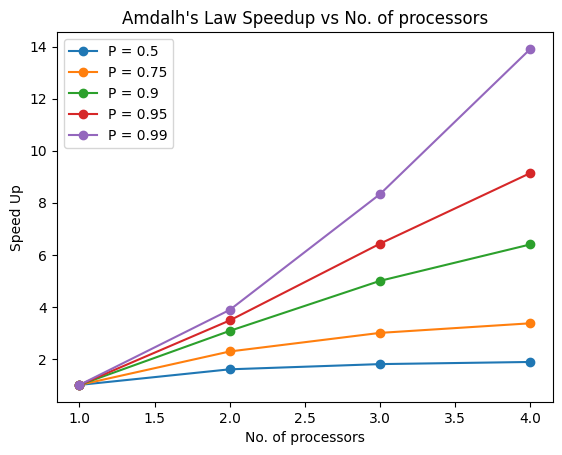

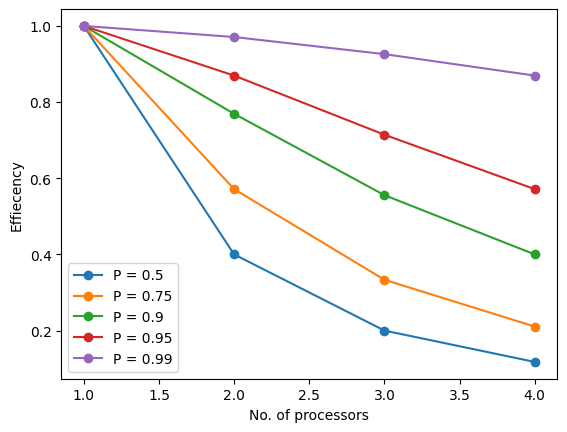

In [3]:
P = [0.5, 0.75, 0.9, 0.95, 0.99]
nopoints = 5
x = np.arange(1, nopoints)
power2 = [x**2 for x in range(1, nopoints)]

speedup = []
efficiency = []

for p in P:
    processors = [Processor(p, n) for n in power2]
    speedup.append(np.array([sp.speedup() for sp in processors]))
    efficiency.append(np.array([sp.efficiency() for sp in processors]))

for index, y_data in enumerate(speedup):
    plt.plot(x, y_data, marker='o', label=f'P = {P[index]}')
plt.title("Amdalh's Law Speedup vs No. of processors")
plt.xlabel("No. of processors")
plt.ylabel("Speed Up")
plt.legend()
plt.show()

for index, y_data in enumerate(efficiency):
    plt.plot(x, y_data, marker='o', label=f'P = {P[index]}')

plt.legend()
plt.xlabel("No. of processors")
plt.ylabel("Effiecency")
plt.show()

**Conclusion:**

The Amdahl’s Law Performance Analyzer was successfully developed and used to evaluate theoretical
speedup and processor efficiency for different parallelizable workloads and processor counts. The
experiment demonstrated that achievable speedup is fundamentally limited by the serial portion of a
workload and that increasing the number of processors produces diminishing returns when the parallelizable
fraction is limited.